# Yearly Trends in ARCHER2 Node-Hour Usage

This notebook looks at the yearly changes in workload across the top software applications used on ARCHER2.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

data_path = Path("../data/archer2_HPC_data_without_overall_and_aOut.csv")
hpc_data = pd.read_csv(data_path)

# Make sure the month column is clean and usable
hpc_data["Year"] = pd.to_numeric(hpc_data["Year"], errors="coerce")
hpc_data["Month"] = pd.to_numeric(hpc_data["Month"], errors="coerce")
hpc_data["Nodeh"] = pd.to_numeric(hpc_data["Nodeh"], errors="coerce").fillna(0)

print("Dataset loaded:", hpc_data.shape)
print(hpc_data.head())

Dataset loaded: (2834, 17)
   Unnamed: 0       Software   Min     Q1  Median      Q3      Max    Jobs  \
0           0           VASP   1.0  512.0   512.0  1792.0  23040.0  106683   
1           1        Unknown   1.0  512.0  1920.0  6400.0  99104.0  733058   
2           2  Met Office UM  26.0  576.0  1296.0  6165.0   7320.0   25300   
3           3       FHI aims   1.0  512.0  1024.0  1024.0   8192.0   88893   
4           4        GROMACS   1.0  512.0  1024.0  1024.0   2560.0   27422   

      Nodeh  PercentUse  Users  Projects  Year  Month  Season  kWh  \
0  886382.6        20.1  139.0      14.0  2026      1  Winter  NaN   
1  794869.1        18.0  512.0      94.0  2026      1  Winter  NaN   
2  418021.1         9.5   43.0       2.0  2026      1  Winter  NaN   
3  171081.4         3.9   33.0       6.0  2026      1  Winter  NaN   
4  165316.9         3.7   40.0       7.0  2026      1  Winter  NaN   

   PercentEnergy  
0            NaN  
1            NaN  
2            NaN  
3      

In [2]:
# Identify the top 5 software by total node-hours across all years
top_software = (
    hpc_data.groupby("Software")["Nodeh"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 software by node-hours:")
print(top_software)

top_names = top_software.index.tolist()
filtered = hpc_data[hpc_data["Software"].isin(top_names)]

Top 5 software by node-hours:
Software
VASP             38813941.0
Unknown          34127812.1
Met Office UM    12963665.3
GROMACS           9546313.3
CP2K              9091777.7
Name: Nodeh, dtype: float64


In [3]:
# Aggregate yearly totals for each software
yearly_trend = (
    filtered.groupby(["Year", "Software"])["Nodeh"]
    .sum()
    .reset_index()
)

pivot_df = yearly_trend.pivot_table(
    index="Year",
    columns="Software",
    values="Nodeh",
    aggfunc="sum"
).fillna(0)

print(pivot_df)

Software       CP2K    GROMACS  Met Office UM    Unknown        VASP
Year                                                                
2022      2382077.5  2119202.2      1437607.1  7201189.9  10245889.7
2023      2364172.2  2507676.7      2091127.3  7092276.5   7521523.1
2024      1626725.7  2036292.4      3992924.1  5974784.4   6669572.2
2025      1784492.0  1969354.9      3189944.3  8620579.2   9216747.6
2026       934310.3   913787.1      2252062.5  5238982.1   5160208.4


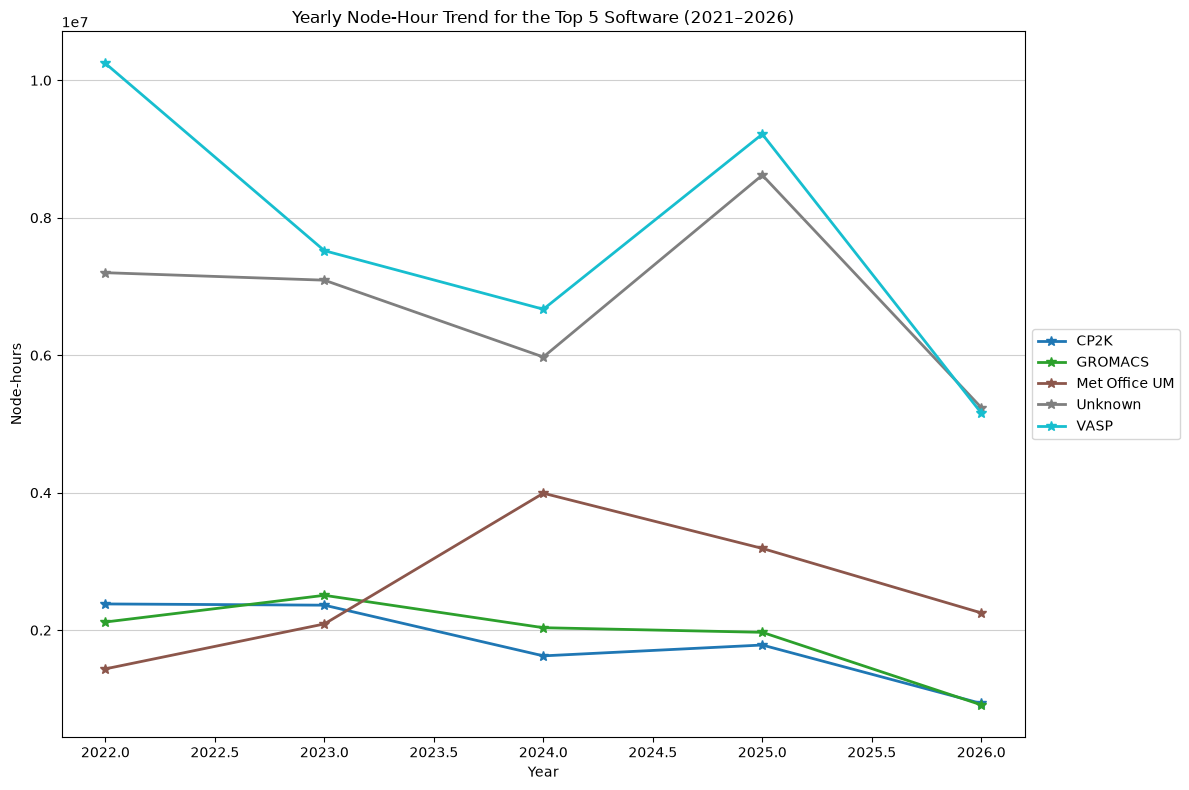

In [4]:
# Plot the yearly trend for each software
pivot_df.plot(
    kind="line",
    figsize=(12, 8),
    linewidth=2,
    marker="*",
    cmap="tab10",
    markersize=7
)

plt.title("Yearly Node-Hour Trend for the Top 5 Software (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Node-hours")
plt.grid(axis="y", linestyle="-", alpha=0.6)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

# Yearly analysis and cumulative trend views

This section brings together the yearly graphing patterns from the original notebook: the overall top software, a cumulative yearly comparison, and a per-year chart for each year in the dataset.


Top 5 software overall:
Software
VASP             38813941.0
Unknown          34127812.1
Met Office UM    12963665.3
GROMACS           9546313.3
CP2K              9091777.7
Name: Nodeh, dtype: float64

Yearly pivot table (cumulative):
Software       CP2K    GROMACS  Met Office UM    Unknown        VASP
Year                                                                
2022      2382077.5  2119202.2      1437607.1  7201189.9  10245889.7
2023      2364172.2  2507676.7      2091127.3  7092276.5   7521523.1
2024      1626725.7  2036292.4      3992924.1  5974784.4   6669572.2
2025      1784492.0  1969354.9      3189944.3  8620579.2   9216747.6
2026       934310.3   913787.1      2252062.5  5238982.1   5160208.4


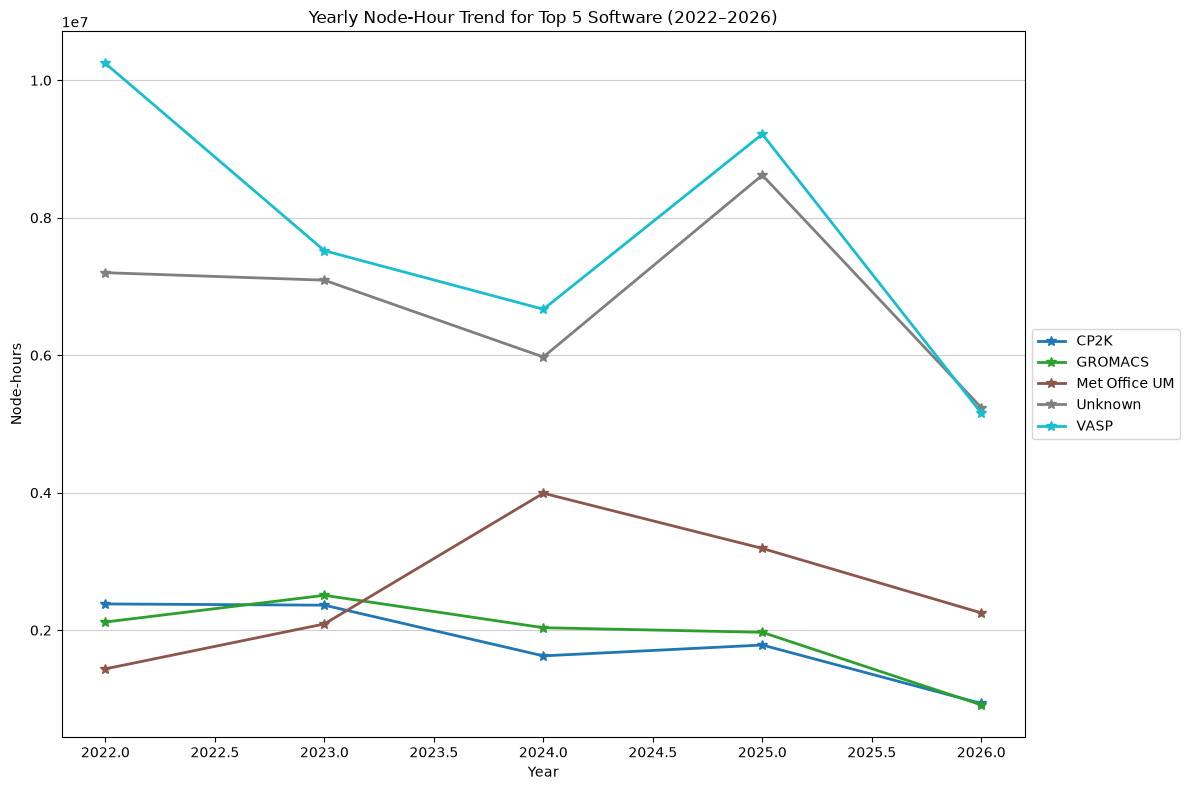

Software
VASP             38813941.0
Unknown          34127812.1
Met Office UM    12963665.3
GROMACS           9546313.3
CP2K              9091777.7
Name: Nodeh, dtype: float64


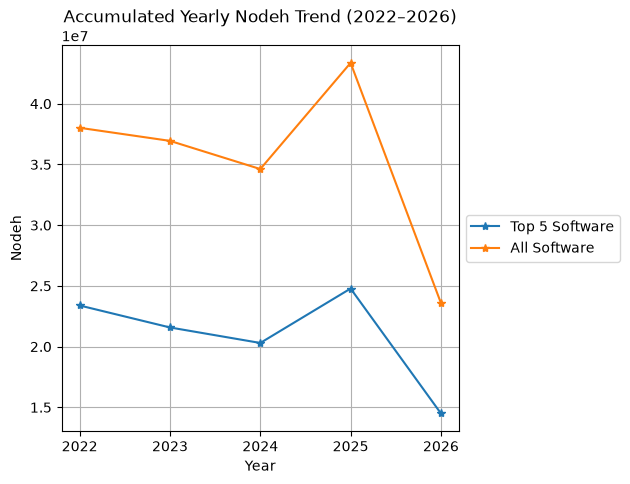

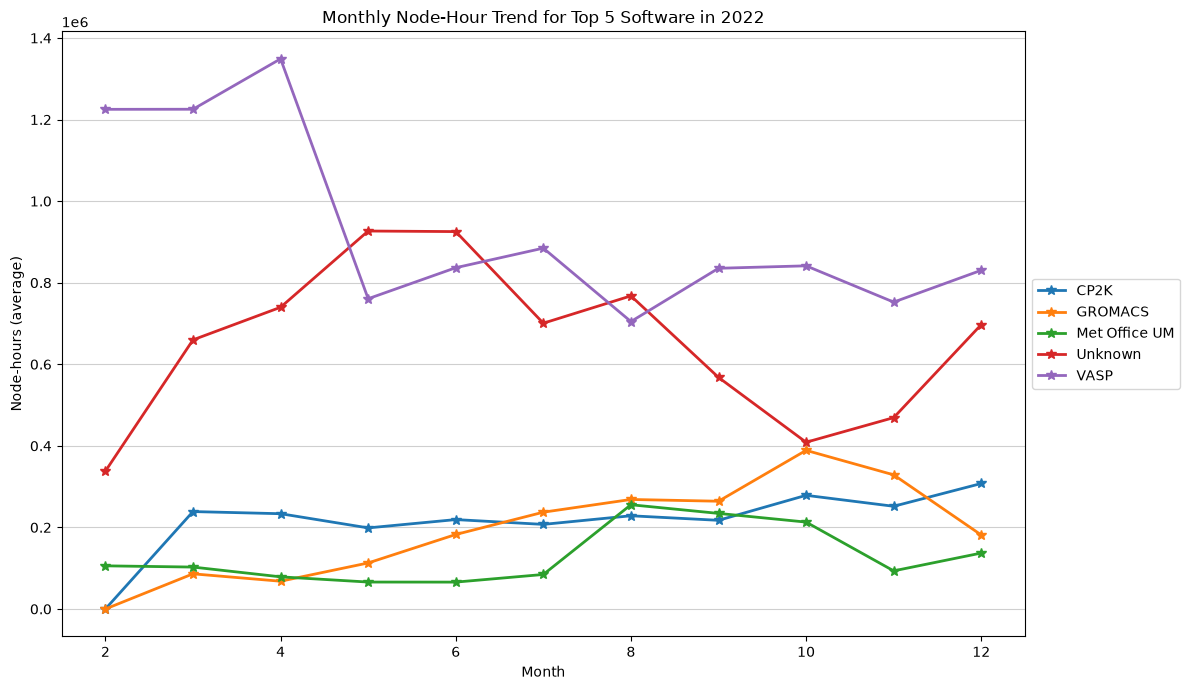

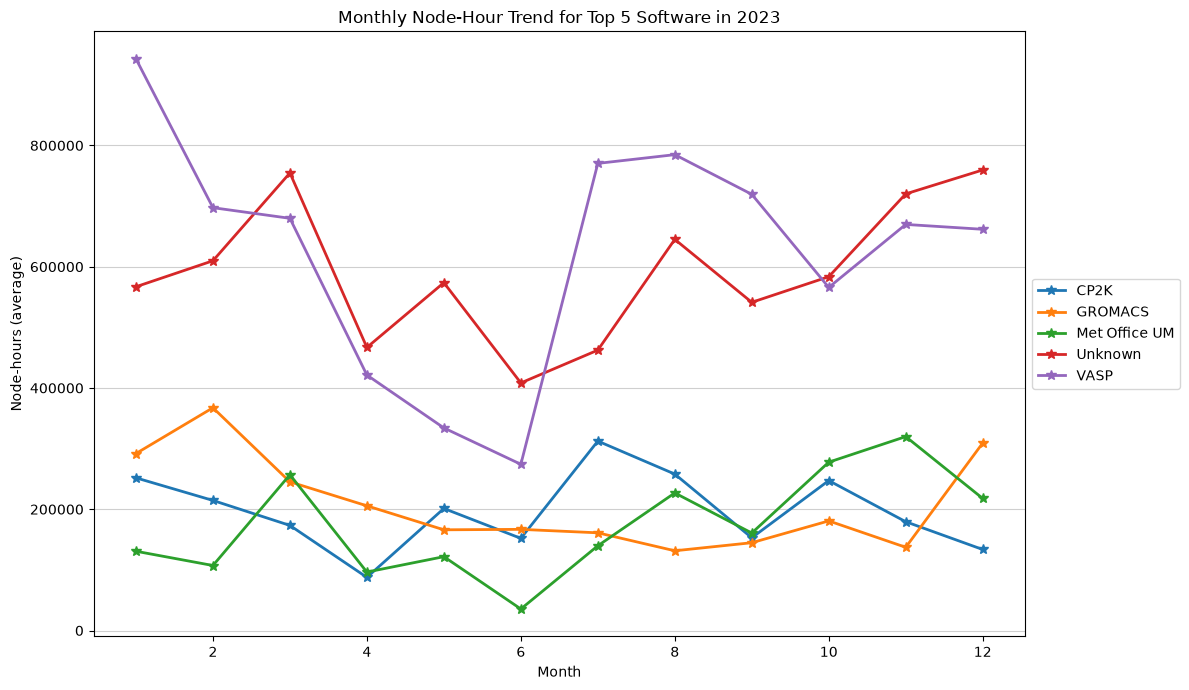

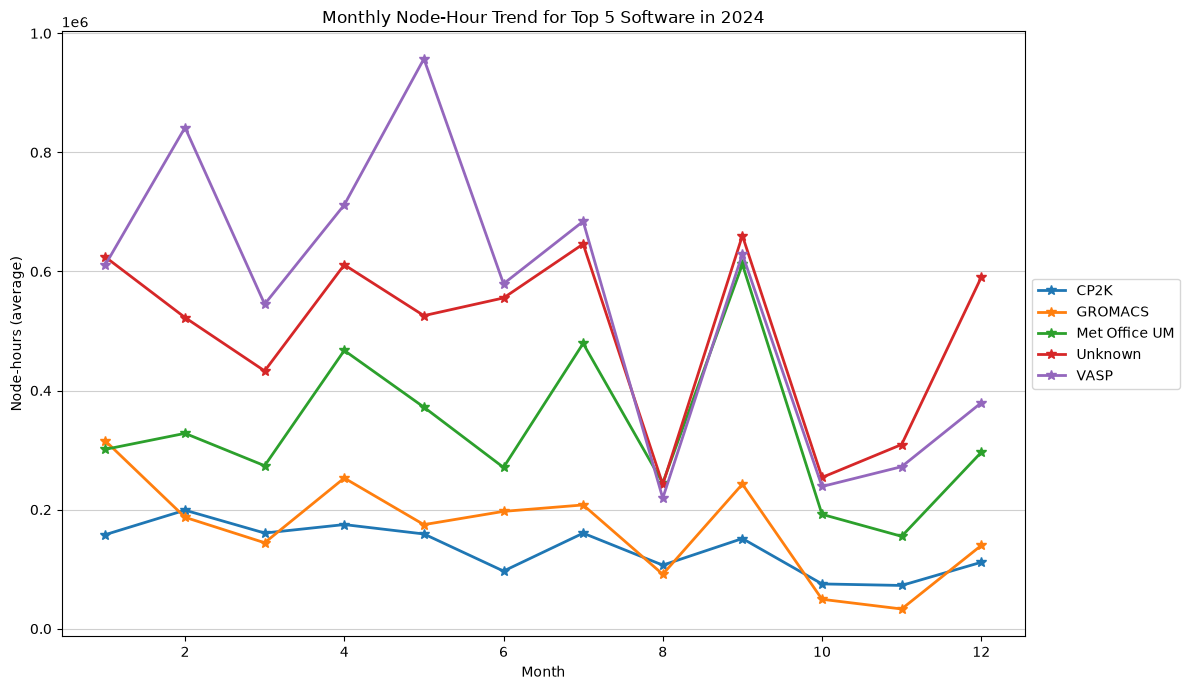

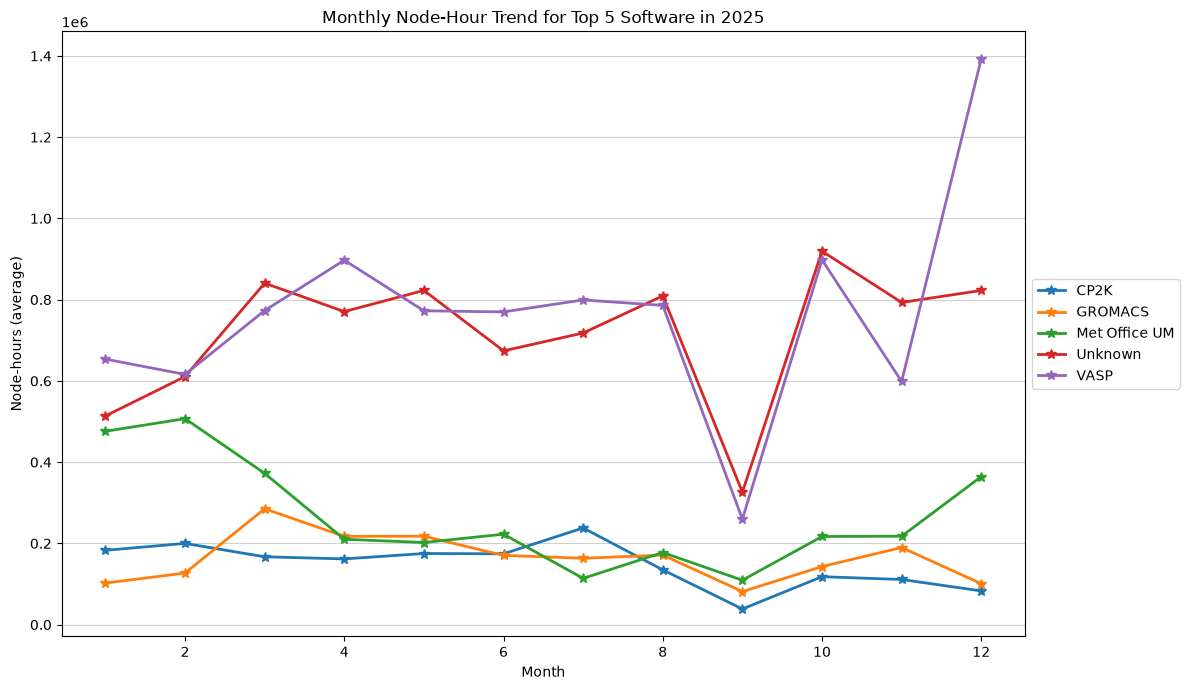

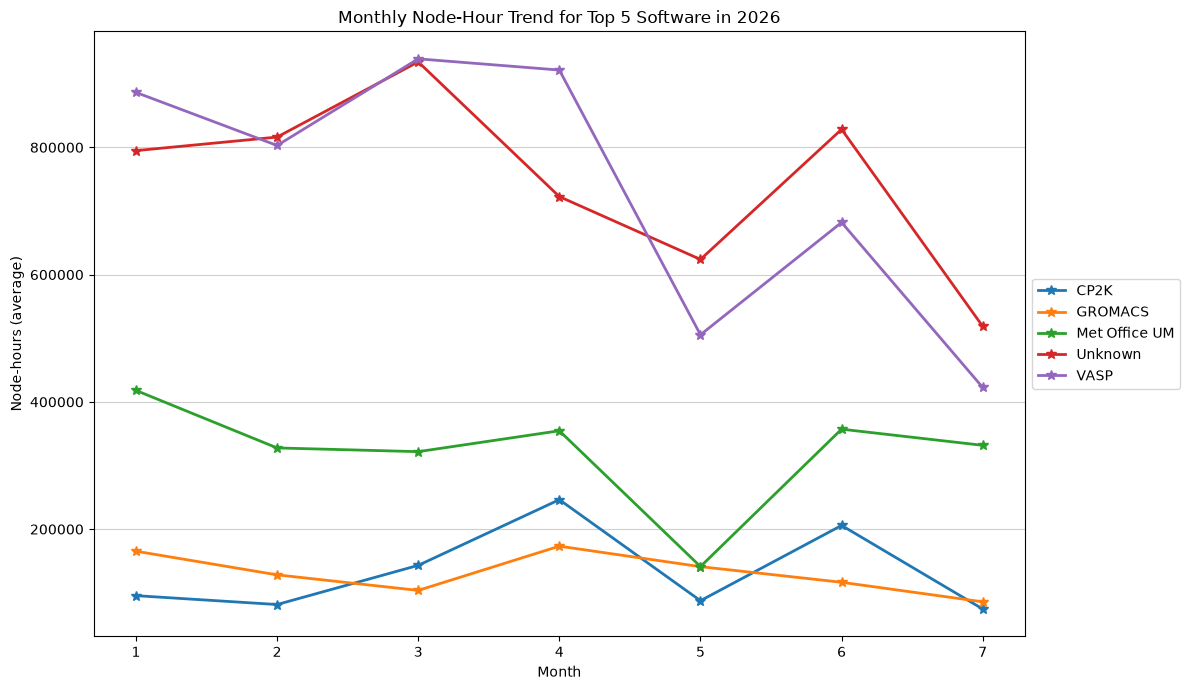

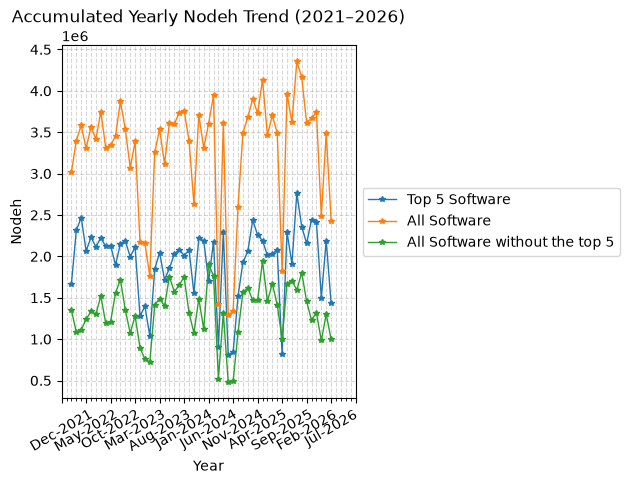

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

hpc_data = pd.read_csv("../data/archer2_HPC_data_without_overall_and_aOut.csv")

# Clean the dataset
hpc_data["Year"] = pd.to_numeric(hpc_data["Year"], errors="coerce")
hpc_data["Month"] = pd.to_numeric(hpc_data["Month"], errors="coerce")
hpc_data["Nodeh"] = pd.to_numeric(hpc_data["Nodeh"], errors="coerce").fillna(0)

# STEP 1: Top 5 software overall (grouped by Software, summed across ALL years)
overall_top5 = (
    hpc_data.groupby("Software")["Nodeh"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 software overall:")
print(overall_top5)

selected_software = overall_top5.index.tolist()
filtered = hpc_data[hpc_data["Software"].isin(selected_software)]

# CHART 1: Yearly trend for top 5 software (SUM - cumulative)
yearly_top5 = (
    filtered.groupby(["Year", "Software"])["Nodeh"]
    .sum()
    .reset_index()
)

pivot_df = yearly_top5.pivot_table(
    index="Year",
    columns="Software",
    values="Nodeh",
    aggfunc="sum"
).fillna(0)

print("\nYearly pivot table (cumulative):")
print(pivot_df)

pivot_df.plot(
    kind="line",
    figsize=(12, 8),
    linewidth=2,
    marker="*",
    cmap="tab10",
    markersize=7
)

plt.title("Yearly Node-Hour Trend for Top 5 Software (2022–2026)")
plt.xlabel("Year")
plt.ylabel("Node-hours")
plt.grid(axis="y", linestyle="-", alpha=0.6)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

# CHART 2: Cumulative yearly trend for ALL software vs Top 5
#Chris' idea


import pandas as pd
import matplotlib.pyplot as plt

hpcData = pd.read_csv("../data/archer2_HPC_data_without_overall_and_aOut.csv")

# Top 5 software overall
overall_top5 = (
    hpcData.groupby("Software")["Nodeh"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
print(overall_top5)

# Filter to top 5
top5_names = overall_top5.index.tolist()
filtered = hpcData[hpcData["Software"].isin(top5_names)]

# Yearly Nodeh for top 5
top5_yearly = (
    filtered.groupby("Year")["Nodeh"]
    .sum()
    .reset_index()
)

# Yearly Nodeh for ALL software
all_yearly = (
    hpcData.groupby("Year")["Nodeh"]
    .sum()
    .reset_index()
)

# Plot
plt.xticks(top5_yearly["Year"].astype(int))

plt.plot(top5_yearly["Year"], top5_yearly["Nodeh"], marker="*", label="Top 5 Software")

plt.plot(all_yearly["Year"], all_yearly["Nodeh"], marker="*", label="All Software")

plt.title("Accumulated Yearly Nodeh Trend (2022–2026)")

plt.xlabel("Year")
plt.ylabel("Nodeh")
plt.grid(True)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()



# CHART 3: Per-year monthly trend (MEAN for individual years)
for year_name, year_group in filtered.groupby("Year"):
    monthly_trend = (
        year_group.groupby(["Month", "Software"])["Nodeh"]
        .mean()  # MEAN for individual years
        .reset_index()
    )

    pivot_year = monthly_trend.pivot_table(
        index="Month",
        columns="Software",
        values="Nodeh",
        aggfunc="mean"
    ).fillna(0)

    fig, ax = plt.subplots(figsize=(12, 7))
    pivot_year.plot(kind="line", ax=ax, marker="*", linewidth=2, markersize=7)
    ax.set_title(f"Monthly Node-Hour Trend for Top 5 Software in {int(year_name)}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Node-hours (average)")
    ax.grid(axis="y", linestyle="-", alpha=0.6)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.show()

    #Chris' idea 2 year and months every 6 months

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
hpcData = pd.read_csv("../data/archer2_HPC_data_without_overall_and_aOut.csv")
hpcData['Month_Index'] = (hpcData['Year'] - 2021) * 12 + (hpcData['Month'] - 12)

# Top 5 software overall
overall_top5 = (
    hpcData.groupby("Software")["Nodeh"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top5_names = overall_top5.index.tolist()

# Filter to top 5
filtered = hpcData[hpcData["Software"].isin(top5_names)]

# Yearly Nodeh for top 5
top5_yearly = (
    filtered.groupby("Month_Index")["Nodeh"]
    .sum()
    .reset_index()
)

# Yearly Nodeh for ALL software
all_yearly = (
    hpcData.groupby("Month_Index")["Nodeh"]
    .sum()
    .reset_index()
)

# all_yearly_without_top5 = (
#     hpcData.query('Software != "top5_names"').groupby('Month_Index')["Nodeh"]
#     .sum()
#     .reset_index()
# )

all_yearly_without_top5 = (
    hpcData[~hpcData["Software"].isin(top5_names)]
    .groupby("Month_Index")["Nodeh"]
    .sum()
    .reset_index()
)


month_name = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

def format_func(value, tick_number):
    # Convert value to integer index
    idx = int(round(value))
    
    # Out-of-bounds check for safety
    if idx < 0 or idx > 55:
        return ""
        
    # December 2021 is index 0 (the 11th month of that year format-wise)
    total_months = 11 + idx
    year = 2021 + (total_months // 12)
    month = total_months % 12
    
    return f"{month_name[month]}-{year}"

# 1. Create your plot
fig, ax = plt.subplots()
# ax.set_yscale('log')
ax.plot(top5_yearly["Month_Index"], top5_yearly["Nodeh"], linewidth=1, marker="*", markersize=4, label="Top 5 Software")
ax.plot(all_yearly["Month_Index"], all_yearly["Nodeh"], linewidth=1, marker="*", markersize=4,label="All Software")
ax.plot(all_yearly_without_top5["Month_Index"], all_yearly_without_top5["Nodeh"], linewidth=1, marker="*", markersize=4, label="All Software without the top 5")


# Apply the formatter and force step ticks so labels align nicely
ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_func))

# Show a tick every 3 months to avoid an overcrowded axis
ax.xaxis.set_major_locator(ticker.MultipleLocator(5)) 
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))



# plt.plot(df['monthlycount'], marker='o', c='crimson')
plt.title("Accumulated Yearly Nodeh Trend (2021–2026)")
plt.xlabel("Year")
plt.ylabel("Nodeh")
plt.xlim(0, 60)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.xticks(rotation=30)
# plt.xlim(0, N - 1)
# plt.xticks(range(0, N, 12), rotation=20) # set major ticks every year
# # plt.gca().set_xticks(range(0, N, 12), rotation=30)
# plt.gca().set_xticks(range(0, N), minor=True)
# plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(format_func))
plt.tight_layout()
plt.show()






# month_name = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# def format_func(value, tick_number):
#     value = int(value)
#     year = 2001 + value // 12
#     month = value % 12
#     # return f"{month+1}-{year}"
#     return f"{month_name[month]}-{year}"

# N = 229
# # create a dataframe resembling the example
# df = pd.DataFrame({'Year': np.repeat(range(2001, 2021), 12)[:N],
#                    'Month': np.tile(range(1, 13), N // 12 + 1)[:N],
#                    'monthlycount': np.random.binomial(5000, .7, N)
#                    })

# plt.plot(df['monthlycount'], marker='o', c='crimson')
# plt.xlim(0, N - 1)
# plt.xticks(range(0, N, 12), rotation=20) # set major ticks every year
# # plt.gca().set_xticks(range(0, N, 12), rotation=30)
# plt.gca().set_xticks(range(0, N), minor=True)
# plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(format_func))
# plt.tight_layout()
# plt.show()


